# 02 · Segmentation and model comparison

Choose k, compare five algorithms fairly, and turn clusters into personas.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from segmentation.data import load_data, clean_data
from segmentation.preprocess import engineer_features, SkewLogTransformer

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
from segmentation.preprocess import prepare
from segmentation.evaluate import sweep_k, compare_models
from segmentation.models import tune_dbscan
from segmentation.segmenter import Segmenter
from segmentation.profile import standardised_means, persona_info
from segmentation.config import PALETTE

In [2]:
df, ids = clean_data(load_data())
feats, X, pre = prepare(df)
print(X.shape)

(8949, 21)


## 1. How many segments?

Elbow, silhouette and Davies-Bouldin for K-Means over k = 2..10.

  File "C:\Users\Om Sawant\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Om Sawant\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Om Sawant\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Om Sawant\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


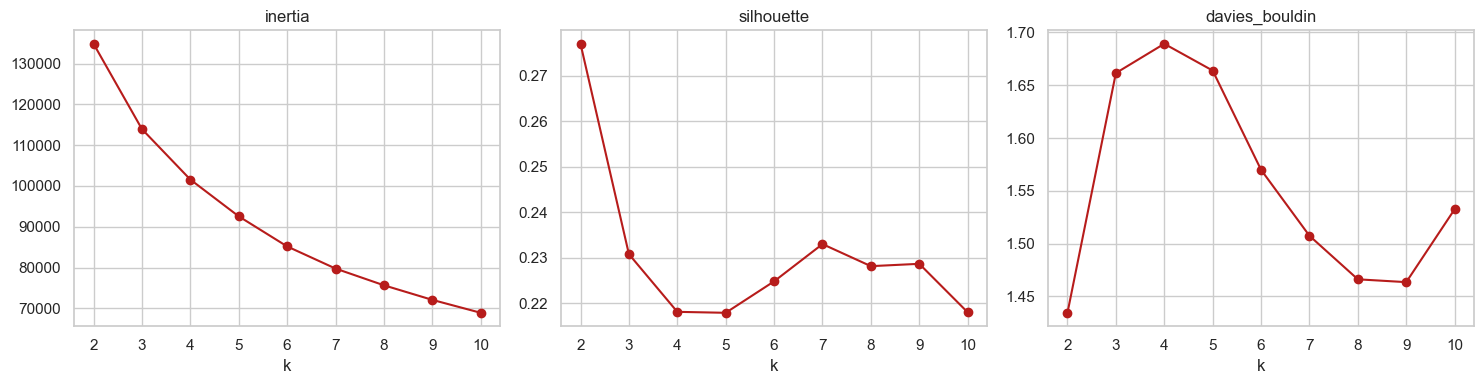

,k,silhouette,davies_bouldin,calinski_harabasz
0,2,0.277,1.434,3521.068
1,3,0.231,1.661,2904.954
2,4,0.218,1.689,2535.420
3,5,0.218,1.664,2304.376
4,6,0.225,1.570,2157.793
5,7,0.233,1.507,2021.812
6,8,0.228,1.466,1896.040
7,9,0.229,1.464,1796.565
8,10,0.218,1.533,1715.918


In [3]:
sweep = sweep_k(X)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['inertia', 'silhouette', 'davies_bouldin']):
    ax.plot(sweep['k'], sweep[col], marker='o', color=PALETTE[0]); ax.set_title(col); ax.set_xlabel('k')
plt.tight_layout(); plt.show()
sweep[['k', 'silhouette', 'davies_bouldin', 'calinski_harabasz']].round(3)

Silhouette peaks at k = 2 (customers who purchase vs those who do not), which is too coarse to act on, and then stays roughly flat at 0.22-0.23 for k = 3..10. **The metrics do not pick k for us**, so the choice has to rest on interpretability and stability. We use **k = 5**: it gives five clearly different behaviours (below) and very stable assignments.

## 2. Compare algorithms at k = 5

Same preprocessing for everyone. Besides silhouette and Davies-Bouldin we measure **stability**: the mean Adjusted Rand Index between the full-data clustering and clusterings of 80% subsamples.

In [4]:
db = tune_dbscan(X)
print({k: v for k, v in db.items() if k != 'labels'})
table, labels = compare_models(X, 5, dbscan=db)
table.round(3)

{'eps': 1.6, 'min_samples': 10, 'n_clusters': 6, 'noise': 0.19421164375907918, 'silhouette': 0.2036447001406167}


,n_clusters,noise,silhouette,davies_bouldin,calinski_harabasz,stability_ari
model,,,,,,
K-Means,5,0.000,0.218,1.664,2304.376,0.982
MiniBatch K-Means,5,0.000,0.196,1.762,2023.917,0.450
Agglomerative (Ward),5,0.000,0.199,1.668,1982.673,0.595
Gaussian Mixture,5,0.000,0.175,1.895,1924.482,0.722
"DBSCAN (eps=1.6, min_samples=10)",6,0.194,0.204,0.856,768.742,NaN


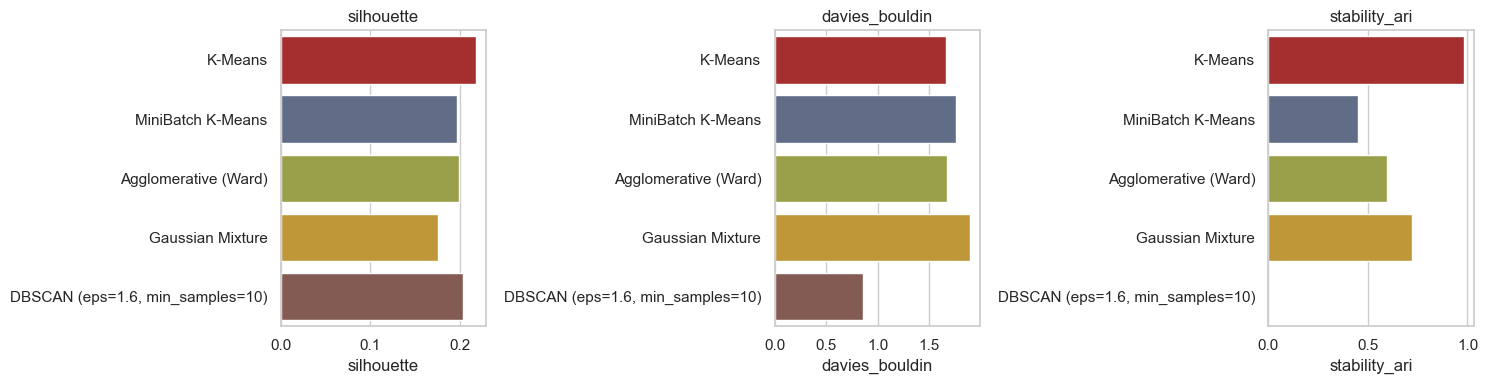

In [5]:
t = table.reset_index()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['silhouette', 'davies_bouldin', 'stability_ari']):
    sns.barplot(data=t, y='model', x=col, hue='model', legend=False, ax=ax, palette=PALETTE[:len(t)]); ax.set_title(col); ax.set_ylabel('')
plt.tight_layout(); plt.show()

K-Means has the best silhouette **and** by far the most reproducible segments. DBSCAN's tuner is constrained to reject the degenerate 'one huge cluster plus noise' answer; even so it discards about 19% of customers as noise, so its scores are not like-for-like.

## 3. Personas

In [6]:
seg = Segmenter(k=5).fit(load_data())
seg.profile_

,persona,customers,share_%,BALANCE,CREDIT_LIMIT,PURCHASES,CASH_ADVANCE,PAYMENTS,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,PRC_FULL_PAYMENT,UTILIZATION,AVG_PURCHASE
cluster,,,,,,,,,,,,,
0,Low-Activity Customers,1231,13.8,17.42,2500.0,159.60,0.00,275.03,0.25,0.00,0.00,0.01,45.65
1,Heavy Revolvers,1715,19.2,2239.94,4500.0,569.85,1708.92,1474.68,0.58,0.27,0.00,0.62,59.19
2,Active Spenders,2234,25.0,1172.26,3000.0,817.78,0.00,865.46,0.75,0.00,0.00,0.40,56.63
3,Savvy Transactors,1758,19.6,98.15,4000.0,921.83,0.00,1024.54,1.00,0.00,0.58,0.03,53.24
4,Cash-Advance Borrowers,2011,22.5,1534.17,3000.0,0.00,1259.18,771.90,0.00,0.25,0.00,0.65,0.00


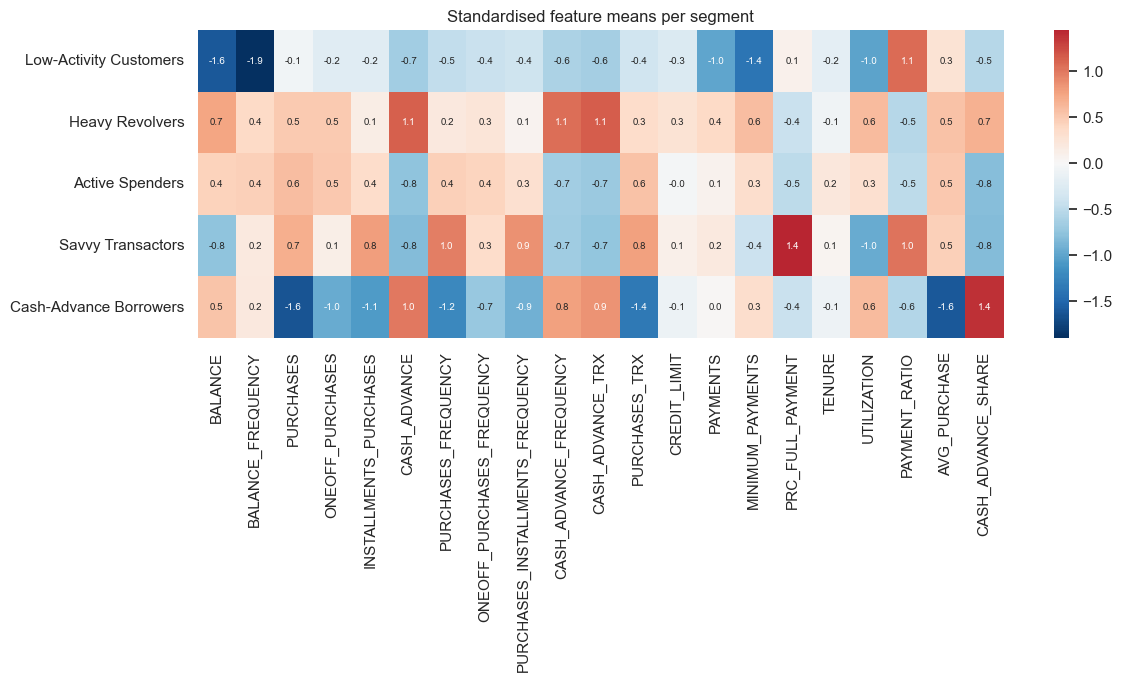

In [7]:
z = standardised_means(seg.X_, seg.labels_, seg.columns_)
z.index = [seg.personas_[int(i)] for i in z.index]
plt.figure(figsize=(13, 4))
sns.heatmap(z, cmap='RdBu_r', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Standardised feature means per segment')
plt.show()

In [8]:
for name in seg.profile_['persona']:
    info = persona_info(name)
    print(f"{name}\n  {info['description']}\n  Action: {info['action']}\n")

Low-Activity Customers
  Small limits, low balances and rare use of the card.
  Action: Re-engagement campaigns, welcome bonuses, or limit-based nudges; churn-risk watch-list.

Heavy Revolvers
  High balances and high utilisation, mixing purchases with frequent cash advances.
  Action: Highest interest revenue but also highest risk: credit-line reviews, instalment-conversion offers.

Active Spenders
  Frequent buyers with sizeable one-off purchases who sometimes revolve.
  Action: Cross-sell instalment plans and spend-based rewards; good candidates for limit increases.

Savvy Transactors
  Buy often, pay the statement in full and keep balances low.
  Action: Reward with cashback / points and premium cards; revenue comes from interchange, not interest.

Cash-Advance Borrowers
  Use the card mainly to withdraw cash and carry a balance; almost no purchases.
  Action: Offer low-rate personal loans or balance-transfer plans; monitor for credit risk.



## 4. Scoring new customers

In [9]:
sample = load_data().sample(8, random_state=1)
seg.predict(sample)

,CUST_ID,segment,persona
4248,C14366,2,Active Spenders
7432,C17635,1,Heavy Revolvers
4668,C14795,2,Active Spenders
5339,C15491,0,Low-Activity Customers
2031,C12094,2,Active Spenders
331,C10342,3,Savvy Transactors
1169,C11212,2,Active Spenders
3448,C13545,4,Cash-Advance Borrowers


## Takeaways

- A log transform plus a few ratio features matters more than the choice of algorithm.
- Silhouette stays near 0.2 for every method: behaviour is a continuum, so segments are useful for **targeting**, not because they are separated islands.
- Reporting stability alongside silhouette exposes how fragile MiniBatch K-Means, Ward and GMM solutions are on this data.